In [16]:
import json
import pandas as pd
import numpy as np

# Charge les données
with open('donki_20260826.json', 'r') as f:
    data = json.load(f)

# Crée un DataFrame
df = pd.DataFrame(data)

# Affiche les infos basiques
print("📊 STRUCTURE DES DONNÉES")
print(f"Nombre de lignes: {len(df)}")
print(f"Nombre de colonnes: {len(df.columns)}\n")

print("Colonnes et types :")
print(df.dtypes)
print("\n")

print("Premières lignes :")
print(df.head())

📊 STRUCTURE DES DONNÉES
Nombre de lignes: 18
Nombre de colonnes: 15

Colonnes et types :
flrID                   str
catalog                 str
instruments          object
beginTime               str
peakTime                str
endTime                 str
classType               str
sourceLocation          str
activeRegionNum       int64
note                    str
submissionTime          str
versionId             int64
link                    str
linkedEvents         object
sentNotifications    object
dtype: object


Premières lignes :
                         flrID      catalog  \
0  2026-08-10T12:34:00-FLR-001  M2M_CATALOG   
1  2026-08-14T06:38:00-FLR-001  M2M_CATALOG   
2  2026-08-16T19:01:00-FLR-001  M2M_CATALOG   
3  2026-08-17T16:18:00-FLR-001  M2M_CATALOG   
4  2026-08-19T18:24:00-FLR-001  M2M_CATALOG   

                                 instruments          beginTime  \
0  [{'displayName': 'GOES-P: EXIS 1.0-8.0'}]  2026-08-10T12:34Z   
1  [{'displayName': 'GOES-P: EXIS 1.0-8

In [17]:
print("\n📈 STATISTIQUES DESCRIPTIVES\n")

print("Colonnes avec valeurs null :")
print(df.isnull().sum())
print("\n")

print("Types de classes :")
print(df['classType'].value_counts())
print("\n")

print("Régions actives :")
print(df['activeRegionNum'].value_counts())
print("\n")

print("Événements avec liens (linkedEvents) :")
df['has_linked'] = df['linkedEvents'].notna()
print(df['has_linked'].value_counts())


📈 STATISTIQUES DESCRIPTIVES

Colonnes avec valeurs null :
flrID                 0
catalog               0
instruments           0
beginTime             0
peakTime              0
endTime               0
classType             0
sourceLocation        0
activeRegionNum       0
note                  0
submissionTime        0
versionId             0
link                  0
linkedEvents          8
sentNotifications    16
dtype: int64


Types de classes :
classType
M1.0    3
M1.8    2
C2.4    1
C4.1    1
C8.2    1
C2.0    1
M8.1    1
M2.9    1
M1.6    1
M1.7    1
M1.9    1
C4.9    1
M6.9    1
C4.7    1
M2.2    1
Name: count, dtype: int64


Régions actives :
activeRegionNum
14513    13
14498     1
14503     1
14506     1
14510     1
14507     1
Name: count, dtype: int64


Événements avec liens (linkedEvents) :
has_linked
True     10
False     8
Name: count, dtype: int64


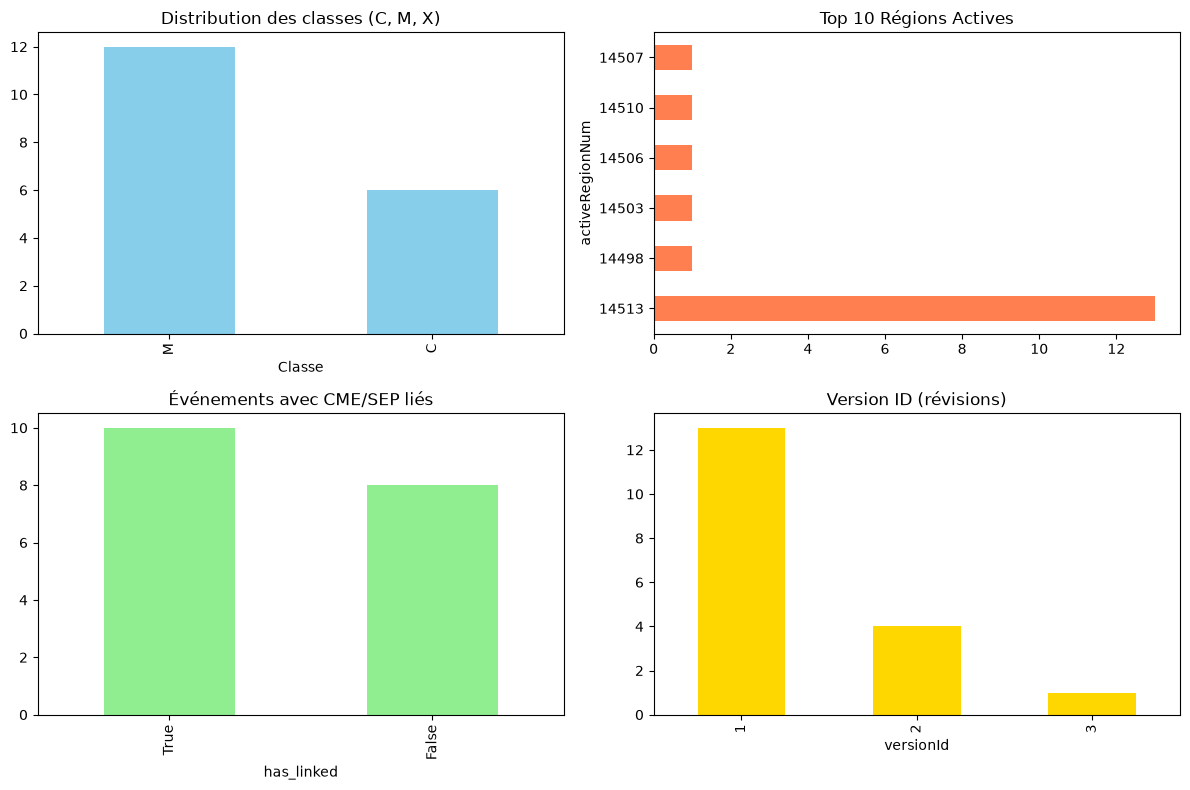

✅ Graphiques affichés


In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Type de classes
df['class_letter'] = df['classType'].str[0]
df['class_letter'].value_counts().plot(kind='bar', ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Distribution des classes (C, M, X)')
axes[0,0].set_xlabel('Classe')

# Régions actives (top 10)
df['activeRegionNum'].value_counts().head(10).plot(kind='barh', ax=axes[0,1], color='coral')
axes[0,1].set_title('Top 10 Régions Actives')

# Événements avec liens
df['has_linked'].value_counts().plot(kind='bar', ax=axes[1,0], color='lightgreen')
axes[1,0].set_title('Événements avec CME/SEP liés')

# Versions (combien de fois révisé)
df['versionId'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='gold')
axes[1,1].set_title('Version ID (révisions)')

plt.tight_layout()
plt.show()

print("✅ Graphiques affichés")

In [19]:
# Convertir en datetime
df['beginTime'] = pd.to_datetime(df['beginTime'])
df['endTime'] = pd.to_datetime(df['endTime'])

print("\n⏰ PATTERNS TEMPORELS\n")

print("Période couverte :")
print(f"Du : {df['beginTime'].min()}")
print(f"Au : {df['beginTime'].max()}\n")

# Événements par jour
df['date'] = df['beginTime'].dt.date
events_per_day = df.groupby('date').size()

print(f"Nombre d'événements par jour :")
print(events_per_day.describe())
print(f"\nJour avec le plus d'événements: {events_per_day.idxmax()} ({events_per_day.max()} événements)")
print(f"Jour avec le moins d'événements: {events_per_day.idxmin()} ({events_per_day.min()} événements)")


⏰ PATTERNS TEMPORELS

Période couverte :
Du : 2026-08-10 12:34:00+00:00
Au : 2026-08-26 12:06:00+00:00

Nombre d'événements par jour :
count    10.000000
mean      1.800000
std       1.619328
min       1.000000
25%       1.000000
50%       1.000000
75%       1.750000
max       6.000000
dtype: float64

Jour avec le plus d'événements: 2026-08-25 (6 événements)
Jour avec le moins d'événements: 2026-08-10 (1 événements)


In [20]:
print("\n🤖 VARIABLES POTENTIELLES POUR LE ML\n")

# Quelles colonnes sont utilisables ?
print("Colonnes numériques :")
print(df.select_dtypes(include=[np.number]).columns.tolist())

print("\nColonnes texte :")
print(df.select_dtypes(include=['object']).columns.tolist())

print("\nColonnes avec le moins de missing :")
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values()
print(missing_pct[missing_pct < 50])


🤖 VARIABLES POTENTIELLES POUR LE ML

Colonnes numériques :
['activeRegionNum', 'versionId']

Colonnes texte :
['flrID', 'catalog', 'instruments', 'peakTime', 'classType', 'sourceLocation', 'note', 'submissionTime', 'link', 'linkedEvents', 'sentNotifications', 'class_letter', 'date']

Colonnes avec le moins de missing :
flrID               0.000000
has_linked          0.000000
link                0.000000
versionId           0.000000
submissionTime      0.000000
note                0.000000
class_letter        0.000000
activeRegionNum     0.000000
classType           0.000000
endTime             0.000000
peakTime            0.000000
beginTime           0.000000
instruments         0.000000
catalog             0.000000
sourceLocation      0.000000
date                0.000000
linkedEvents       44.444444
dtype: float64
